In [1]:
!pip install pandas numpy matplotlib seaborn scikit-learn imbalanced-learn

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split


In [3]:
df = sns.load_dataset('titanic')

In [4]:
print(df.head()) 

   survived  pclass     sex   age  sibsp  parch     fare embarked  class  \
0         0       3    male  22.0      1      0   7.2500        S  Third   
1         1       1  female  38.0      1      0  71.2833        C  First   
2         1       3  female  26.0      0      0   7.9250        S  Third   
3         1       1  female  35.0      1      0  53.1000        S  First   
4         0       3    male  35.0      0      0   8.0500        S  Third   

     who  adult_male deck  embark_town alive  alone  
0    man        True  NaN  Southampton    no  False  
1  woman       False    C    Cherbourg   yes  False  
2  woman       False  NaN  Southampton   yes   True  
3  woman       False    C  Southampton   yes  False  
4    man        True  NaN  Southampton    no   True  


In [5]:
print("Nombre de lignes :", df.shape[0])
print("Nombre de colonnes :", df.shape[1]) 

Nombre de lignes : 891
Nombre de colonnes : 15


In [6]:
print(df.dtypes) 

survived          int64
pclass            int64
sex                 str
age             float64
sibsp             int64
parch             int64
fare            float64
embarked            str
class          category
who                 str
adult_male         bool
deck           category
embark_town         str
alive               str
alone              bool
dtype: object


In [7]:
df.isnull().sum() 

survived         0
pclass           0
sex              0
age            177
sibsp            0
parch            0
fare             0
embarked         2
class            0
who              0
adult_male       0
deck           688
embark_town      2
alive            0
alone            0
dtype: int64

In [8]:
X = df.drop('survived', axis=1)
y = df['survived'] 

In [9]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
) 

In [10]:
print("X_train :", X_train.shape)
print("X_test :", X_test.shape)

print("y_train :", y_train.shape)
print("y_test :", y_test.shape) 

X_train : (712, 14)
X_test : (179, 14)
y_train : (712,)
y_test : (179,)


In [11]:
print("Train :")
print(y_train.value_counts(normalize=True))

print("Test :")
print(y_test.value_counts(normalize=True)) 

Train :
survived
0    0.616573
1    0.383427
Name: proportion, dtype: float64
Test :
survived
0    0.614525
1    0.385475
Name: proportion, dtype: float64


In [12]:
print("Valeurs manquantes dans Train :")
print(X_train.isnull().sum())

print("\nPourcentage de valeurs manquantes :")
print((X_train.isnull().mean() * 100).round(2)) 

Valeurs manquantes dans Train :
pclass           0
sex              0
age            137
sibsp            0
parch            0
fare             0
embarked         2
class            0
who              0
adult_male       0
deck           553
embark_town      2
alive            0
alone            0
dtype: int64

Pourcentage de valeurs manquantes :
pclass          0.00
sex             0.00
age            19.24
sibsp           0.00
parch           0.00
fare            0.00
embarked        0.28
class           0.00
who             0.00
adult_male      0.00
deck           77.67
embark_town     0.28
alive           0.00
alone           0.00
dtype: float64


In [13]:
missing_rate = X_train.isnull().mean()

cols_to_drop = missing_rate[
    missing_rate > 0.40
].index.tolist()

print("Colonnes à supprimer :", cols_to_drop)

X_train = X_train.drop(columns=cols_to_drop)
X_test = X_test.drop(columns=cols_to_drop) 

Colonnes à supprimer : ['deck']


In [14]:
from sklearn.impute import SimpleImputer

num_cols = X_train.select_dtypes(
    include=np.number
).columns

imputer_num = SimpleImputer(strategy='median')

X_train[num_cols] = imputer_num.fit_transform(
    X_train[num_cols]
)

X_test[num_cols] = imputer_num.transform(
    X_test[num_cols]
) 

In [15]:
cat_cols = X_train.select_dtypes(
    exclude=np.number
).columns

imputer_cat = SimpleImputer(strategy='most_frequent')

X_train[cat_cols] = imputer_cat.fit_transform(
    X_train[cat_cols]
)

X_test[cat_cols] = imputer_cat.transform(
    X_test[cat_cols]
)

In [16]:
print("Train :")
print(X_train.isnull().sum())

print("\nTest :")
print(X_test.isnull().sum())

Train :
pclass         0
sex            0
age            0
sibsp          0
parch          0
fare           0
embarked       0
class          0
who            0
adult_male     0
embark_town    0
alive          0
alone          0
dtype: int64

Test :
pclass         0
sex            0
age            0
sibsp          0
parch          0
fare           0
embarked       0
class          0
who            0
adult_male     0
embark_town    0
alive          0
alone          0
dtype: int64


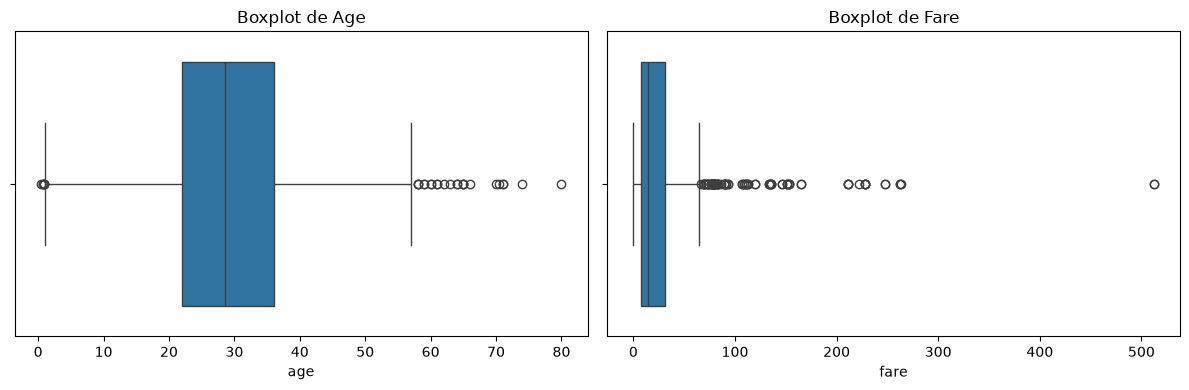

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.boxplot(x=X_train['age'], ax=axes[0])
axes[0].set_title("Boxplot de Age")

sns.boxplot(x=X_train['fare'], ax=axes[1])
axes[1].set_title("Boxplot de Fare")

plt.tight_layout()
plt.show() 

In [18]:
def detect_outliers(data, column):

    Q1 = data[column].quantile(0.25)
    Q3 = data[column].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = data[
        (data[column] < lower) |
        (data[column] > upper)
    ]

    print("Variable :", column)
    print("Q1 :", Q1)
    print("Q3 :", Q3)
    print("IQR :", IQR)
    print("Limite inférieure :", lower)
    print("Limite supérieure :", upper)
    print("Nombre d'outliers :", len(outliers))

    return lower, upper

age_bounds = detect_outliers(X_train, 'age')
fare_bounds = detect_outliers(X_train, 'fare')

Variable : age
Q1 : 22.0
Q3 : 36.0
IQR : 14.0
Limite inférieure : 1.0
Limite supérieure : 57.0
Nombre d'outliers : 29
Variable : fare
Q1 : 7.8958
Q3 : 31.0
IQR : 23.1042
Limite inférieure : -26.7605
Limite supérieure : 65.6563
Nombre d'outliers : 91


In [19]:
for col, bounds in [
    ('age', age_bounds),
    ('fare', fare_bounds)
]:

    lower, upper = bounds

    median_value = X_train[col].median()

    X_train[col] = X_train[col].mask(
        (X_train[col] < lower) |
        (X_train[col] > upper),
        median_value
    )

    X_test[col] = X_test[col].mask(
        (X_test[col] < lower) |
        (X_test[col] > upper),
        median_value
    )

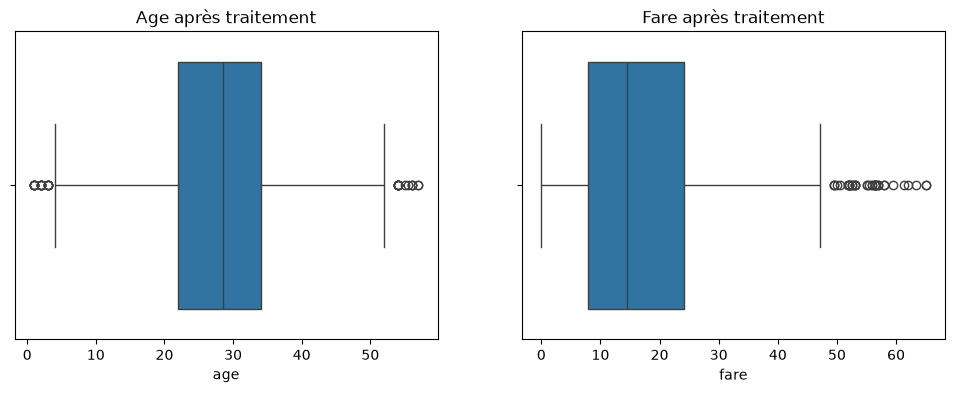

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.boxplot(x=X_train['age'], ax=axes[0])
axes[0].set_title("Age après traitement")

sns.boxplot(x=X_train['fare'], ax=axes[1])
axes[1].set_title("Fare après traitement")

plt.show()

In [21]:
for col in ['age', 'fare']:

    lower, upper = (
        age_bounds if col == 'age' else fare_bounds
    )

    outliers_remaining = X_train[
        (X_train[col] < lower) |
        (X_train[col] > upper)
    ]

    print(f"\nVariable : {col}")
    print("Outliers restants selon les limites initiales :",
          len(outliers_remaining))


Variable : age
Outliers restants selon les limites initiales : 0

Variable : fare
Outliers restants selon les limites initiales : 0


In [23]:
categorical_cols = X_train.select_dtypes(
    include=['object', 'str', 'category']
).columns
print("Variables catégorielles :")
print(list(categorical_cols))

Variables catégorielles :
['sex', 'embarked', 'class', 'who', 'adult_male', 'embark_town', 'alive', 'alone']


In [24]:
from sklearn.preprocessing import OneHotEncoder
encoder = OneHotEncoder(
    handle_unknown='ignore',
    sparse_output=False
)

X_train_cat = encoder.fit_transform(
    X_train[['sex', 'embarked']]
)

X_test_cat = encoder.transform(
    X_test[['sex', 'embarked']]
)

print(encoder.get_feature_names_out())

['sex_female' 'sex_male' 'embarked_C' 'embarked_Q' 'embarked_S']


In [27]:
print(X_train['pclass'].value_counts()) 

pclass
3.0    391
1.0    171
2.0    150
Name: count, dtype: int64


In [28]:
numeric_cols = X_train.select_dtypes(include=np.number).columns

print("Colonnes numériques :", numeric_cols.tolist())

Colonnes numériques : ['pclass', 'age', 'sibsp', 'parch', 'fare']


In [29]:
from sklearn.preprocessing import MinMaxScaler

scaler_minmax = MinMaxScaler()

X_train_minmax = scaler_minmax.fit_transform(
    X_train[['age', 'sibsp', 'parch', 'fare']]
)

X_test_minmax = scaler_minmax.transform(
    X_test[['age', 'sibsp', 'parch', 'fare']]
)

print("Train après normalisation :")
print(pd.DataFrame(
    X_train_minmax,
    columns=['age', 'sibsp', 'parch', 'fare']
).head())

Train après normalisation :
        age  sibsp     parch      fare
0  0.491071  0.000  0.000000  0.869166
1  0.491071  0.000  0.000000  0.000000
2  0.491071  0.000  0.000000  0.222372
3  0.303571  0.000  0.166667  0.143846
4  0.535714  0.125  0.166667  0.403846


In [30]:
print("Minimum :", X_train_minmax.min(axis=0))
print("Maximum :", X_train_minmax.max(axis=0)) 

Minimum : [0. 0. 0. 0.]
Maximum : [1. 1. 1. 1.]


In [31]:
from sklearn.preprocessing import StandardScaler

scaler_standard = StandardScaler()

X_train_standard = scaler_standard.fit_transform(
    X_train[['age', 'sibsp', 'parch', 'fare']]
)

X_test_standard = scaler_standard.transform(
    X_test[['age', 'sibsp', 'parch', 'fare']]
) 

In [32]:
print("Moyenne :")
print(X_train_standard.mean(axis=0))

print("Écart-type :")
print(X_train_standard.std(axis=0)) 

Moyenne :
[ 1.74641824e-17 -5.61348720e-18 -1.62167408e-17  1.12269744e-16]
Écart-type :
[1. 1. 1. 1.]


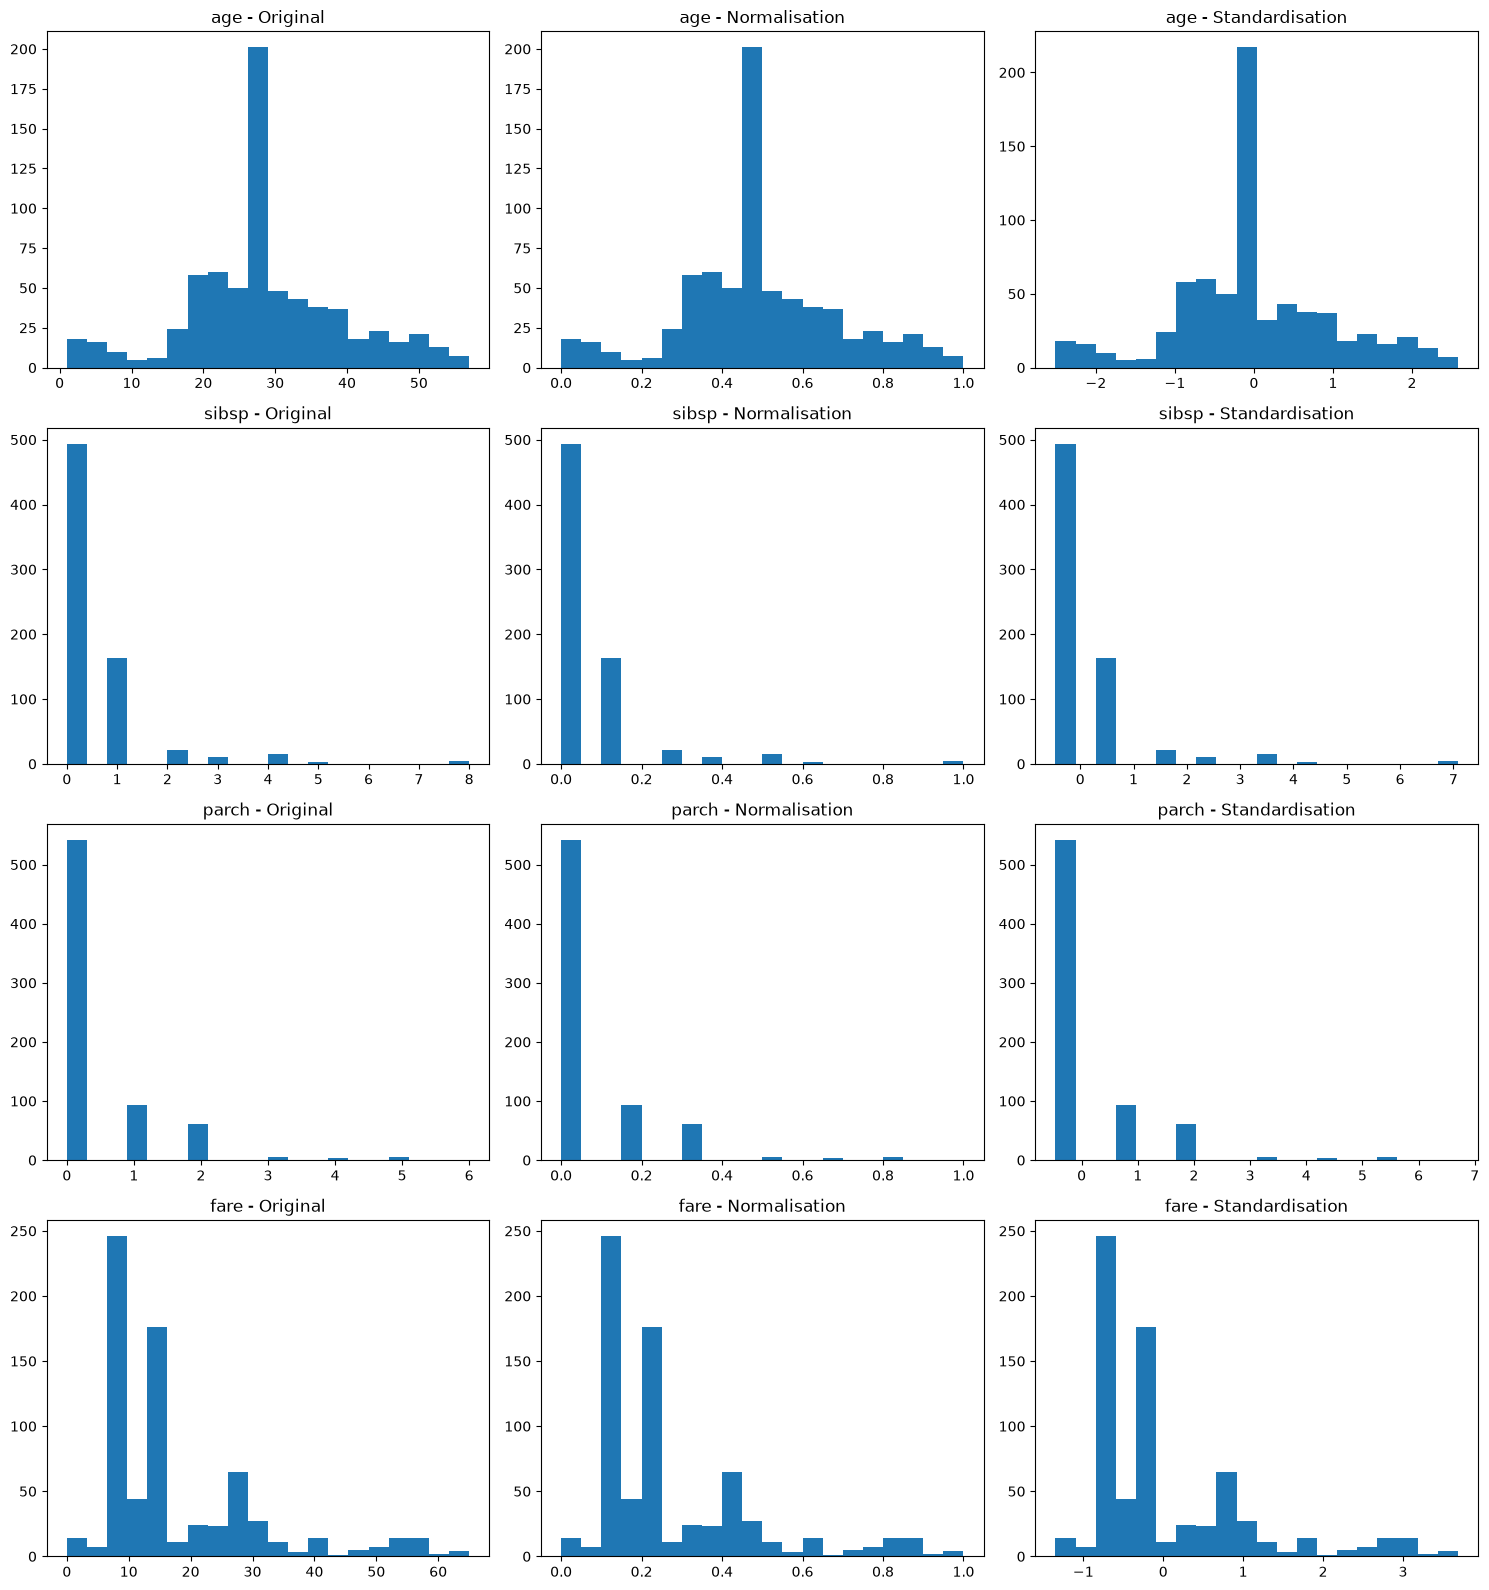

In [34]:
fig, axes = plt.subplots(4, 3, figsize=(15, 16))

numeric_cols = ['age', 'sibsp', 'parch', 'fare']

for i, col in enumerate(numeric_cols):

    axes[i, 0].hist(X_train[col], bins=20)
    axes[i, 0].set_title(f"{col} - Original")

    axes[i, 1].hist(X_train_minmax[:, i], bins=20)
    axes[i, 1].set_title(f"{col} - Normalisation")

    axes[i, 2].hist(X_train_standard[:, i], bins=20)
    axes[i, 2].set_title(f"{col} - Standardisation")

plt.tight_layout()
plt.show()

In [35]:
print("Nombre d'observations par classe :")
print(y_train.value_counts()) 

Nombre d'observations par classe :
survived
0    439
1    273
Name: count, dtype: int64


In [36]:
print("Pourcentage par classe :")
print(y_train.value_counts(normalize=True) * 100)

Pourcentage par classe :
survived
0    61.657303
1    38.342697
Name: proportion, dtype: float64


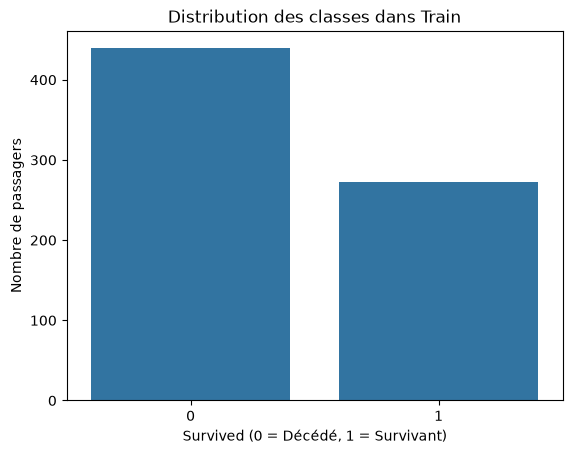

In [37]:
sns.countplot(x=y_train)

plt.title("Distribution des classes dans Train")
plt.xlabel("Survived (0 = Décédé, 1 = Survivant)")
plt.ylabel("Nombre de passagers")

plt.show()

In [41]:
from sklearn.utils import resample
train_data = X_train[['age', 'fare', 'pclass', 'sibsp', 'parch']].copy()

train_data['survived'] = y_train

majority = train_data[
    train_data['survived'] == 0
]
minority = train_data[
    train_data['survived'] == 1
]
majority_downsampled = resample(
    majority,
    replace=False,
    n_samples=len(minority),
    random_state=42
)
df_under = pd.concat([
    majority_downsampled,
    minority
])
print("Avant Undersampling :")
print(train_data['survived'].value_counts())

print("\nAprès Undersampling :")
print(df_under['survived'].value_counts()) 

Avant Undersampling :
survived
0    439
1    273
Name: count, dtype: int64

Après Undersampling :
survived
0    273
1    273
Name: count, dtype: int64


In [42]:
from imblearn.over_sampling import SMOTE
from sklearn.preprocessing import StandardScaler

features = ['age', 'fare', 'pclass', 'sibsp', 'parch']

X_train_num = X_train[features].copy()
X_test_num = X_test[features].copy()

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train_num)
X_test_scaled = scaler.transform(X_test_num)

smote = SMOTE(random_state=42)

X_train_smote, y_train_smote = smote.fit_resample(
    X_train_scaled,
    y_train
)
print("Avant SMOTE :")
print(y_train.value_counts())

print("\nAprès SMOTE :")
print(y_train_smote.value_counts())

Avant SMOTE :
survived
0    439
1    273
Name: count, dtype: int64

Après SMOTE :
survived
1    439
0    439
Name: count, dtype: int64
